# Basic Input/Output (I/O) in Python

Programs read data from files and write results to files. This lesson covers text files, encodings, CSV, JSON and binary files.

**After this lesson you can:**

1. Open files safely with `with open(...)`.
2. Select the correct mode and encoding.
3. Read and write CSV and JSON with the standard library.
4. Compare file formats by size and speed.

The examples write into a temporary folder, so the repository stays clean.

## 1. Open, Read and Write Text

`open(path, mode, encoding=...)` returns a file object. The `with` statement closes the file automatically, also when an error occurs.

| Mode | Meaning |
| :--- | :--- |
| `"r"` | read text (default) |
| `"w"` | write text; **deletes** existing content |
| `"a"` | append text at the end |
| `"x"` | create; error if the file exists |
| `"rb"`, `"wb"` | read / write bytes |

Always give `encoding="utf-8"` for text. The default encoding depends on the operating system, and Turkish characters can break on Windows without it.

In [1]:
import tempfile
from pathlib import Path

folder = Path(tempfile.mkdtemp())
notes = folder / "notes.txt"

with open(notes, "w", encoding="utf-8") as f:
    f.write("Günaydın İstanbul!\n")
    f.write("Line two\n")
with open(notes, "a", encoding="utf-8") as f:
    f.writelines(["Line three\n", "Line four\n"])

with open(notes, encoding="utf-8") as f:
    print("read():", repr(f.read()))

with open(notes, encoding="utf-8") as f:
    for number, line in enumerate(f, start=1):      # line by line: memory-friendly
        print(number, line.rstrip("\n"))

read(): 'Günaydın İstanbul!\nLine two\nLine three\nLine four\n'
1 Günaydın İstanbul!
2 Line two
3 Line three
4 Line four


## 2. Encodings

A file stores bytes. An **encoding** maps characters to bytes. UTF-8 is the standard for text today. If you read bytes with the wrong encoding, you get wrong characters or an error.

In [2]:
text = "ğüşıöç"
utf8 = text.encode("utf-8")
print("UTF-8 bytes:", utf8, f"({len(utf8)} bytes for {len(text)} characters)")
print("Decoded as cp1252:", utf8.decode("cp1252", errors="replace"))
try:
    utf8.decode("ascii")
except UnicodeDecodeError as err:
    print("ASCII cannot decode it:", err.reason)

UTF-8 bytes: b'\xc4\x9f\xc3\xbc\xc5\x9f\xc4\xb1\xc3\xb6\xc3\xa7' (12 bytes for 6 characters)
Decoded as cp1252: ÄŸÃ¼ÅŸÄ±Ã¶Ã§
ASCII cannot decode it: ordinal not in range(128)


## 3. CSV Files

**CSV** (comma-separated values) stores a table as text, one row per line. The `csv` module handles quotes and commas inside values. `csv.DictReader` returns each row as a dict. All CSV values are text, so convert numbers yourself.

The data below is a synthetic sales table.

In [3]:
import csv
import random

random.seed(1)
rows = [{"order_id": i, "city": random.choice(["Ankara", "İzmir", "Bursa"]),
         "amount": round(random.uniform(10, 500), 2), "note": random.choice(["", "gift, wrap", 'urgent "today"'])}
        for i in range(1, 2001)]

sales_csv = folder / "sales.csv"
with open(sales_csv, "w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=rows[0].keys())
    writer.writeheader()
    writer.writerows(rows)

print(sales_csv.read_text(encoding="utf-8").splitlines()[:4])

with open(sales_csv, newline="", encoding="utf-8") as f:
    loaded = list(csv.DictReader(f))
total = sum(float(r["amount"]) for r in loaded)
print(f"\n{len(loaded)} rows read, total amount {total:,.2f}")
print("first row:", loaded[0])

['order_id,city,amount,note', '1,Ankara,288.91,', '2,İzmir,67.78,"gift, wrap"', '3,İzmir,329.28,']

2000 rows read, total amount 511,722.65
first row: {'order_id': '1', 'city': 'Ankara', 'amount': '288.91', 'note': ''}


## 4. JSON Files

**JSON** stores nested data: objects (dicts), arrays (lists), strings, numbers, booleans and `null`. Web APIs use JSON. `json.dump` writes Python objects; `json.load` reads them back.

In [4]:
import json

config = {"model": "gpt2", "max_tokens": 128, "temperature": 0.7, "stop": ["\n\n"], "debug": False, "seed": None}
cfg_file = folder / "config.json"
cfg_file.write_text(json.dumps(config, indent=2, ensure_ascii=False), encoding="utf-8")
print(cfg_file.read_text(encoding="utf-8"))
print("round trip equal:", json.loads(cfg_file.read_text(encoding="utf-8")) == config)

sales_json = folder / "sales.json"
sales_json.write_text(json.dumps(rows, ensure_ascii=False), encoding="utf-8")

{
  "model": "gpt2",
  "max_tokens": 128,
  "temperature": 0.7,
  "stop": [
    "\n\n"
  ],
  "debug": false,
  "seed": null
}
round trip equal: True


150274

## 5. Binary Files and Formats Compared

Binary formats store values as bytes, not as text. `pickle` saves almost any Python object, but **never load a pickle from an untrusted source**: loading can run arbitrary code. The experiment compares the same 2,000 rows as CSV, JSON and pickle.

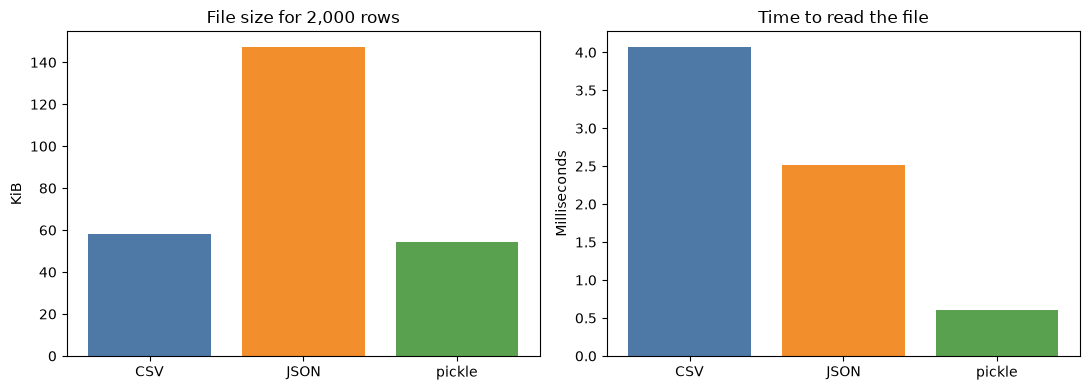

CSV        58.2 KiB    4.07 ms
JSON      147.4 KiB    2.52 ms
pickle     54.5 KiB    0.61 ms


In [5]:
import pickle
import time

import matplotlib.pyplot as plt

sales_pkl = folder / "sales.pkl"
sales_pkl.write_bytes(pickle.dumps(rows))

def read_csv():
    with open(sales_csv, newline="", encoding="utf-8") as f:
        return list(csv.DictReader(f))

readers = {"CSV": (sales_csv, read_csv),
           "JSON": (sales_json, lambda: json.loads(sales_json.read_text(encoding="utf-8"))),
           "pickle": (sales_pkl, lambda: pickle.loads(sales_pkl.read_bytes()))}
sizes, times = {}, {}
for name, (path, fn) in readers.items():
    sizes[name] = path.stat().st_size / 1024
    t = time.perf_counter()
    for _ in range(20):
        fn()
    times[name] = (time.perf_counter() - t) / 20 * 1000

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
colors = ["#4E79A7", "#F28E2B", "#59A14F"]
ax1.bar(sizes.keys(), sizes.values(), color=colors)
ax1.set(title="File size for 2,000 rows", ylabel="KiB")
ax2.bar(times.keys(), times.values(), color=colors)
ax2.set(title="Time to read the file", ylabel="Milliseconds")
plt.tight_layout()
plt.show()
for name in readers:
    print(f"{name:<7} {sizes[name]:7.1f} KiB  {times[name]:6.2f} ms")

JSON repeats every key in every row, so it is the largest. Pickle is compact and fast because it stores Python objects directly, but only Python can read it. CSV is readable by every tool, but every value is text. For large tables, data teams use columnar binary formats such as **Parquet** (M08).

*Insight: Use `with open(...)` and an explicit `encoding="utf-8"` for every text file. Use CSV or JSON to exchange data with other tools and people, and never unpickle data from an untrusted source.*

## Real-World Use Case or Analogy

File formats are like **ways to send a document**: a CSV is a printed table that anyone can read; JSON is a filled-in form with labels next to each value; a pickle is a sealed box that only the same kind of machine can open safely.

In practice, configuration lives in JSON or YAML, data exchange with business teams uses CSV, and machine-learning pipelines store large datasets as Parquet and trained models in formats such as safetensors or ONNX (M35).